# 03 · Download (RBP-ARK)

The splice maps in notebook 07 need the eCLIP reads (BAM files), not only the windows. RBP-ARK offers three ways to get files:

| Way | Good for | How |
| --- | --- | --- |
| BDBag | one experiment | the Download BDBag button on its page: a small archive that lists every file with its address, size and checksum |
| API file list | a few files, from a script | what this notebook does |
| Globus | many experiments or whole folders | log in with Globus and transfer to your computer or cluster |

Please download only what you need. The public server is shared, and bulk downloads have taken it offline before.

On Google Colab, run the next cell first in every session. It copies this repository onto the Colab machine and, with `SAVE_TO_DRIVE = True`, saves results and the figure to `My Drive/CS3_workflow` (Colab asks for permission to connect your Drive). `LITE = True` uses a small subset of the data that fits free Colab. On your own computer the cell does nothing.

In [ ]:
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess
    REPO = "https://github.com/yeolab/encode-rbp-case-study"
    CLONE = "/content/encode-rbp-case-study"
    LITE = True    # True: small subset of the data, fits free Colab (about 1 h). False: all the data (5-8 h, ~50 GB)
    SAVE_TO_DRIVE = True    # results and the figure in My Drive/CS3_workflow; False: on this Colab machine only
    if not os.path.isdir(CLONE):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, CLONE], check=True)
    WORKFLOW = CLONE + "/notebooks/workflow"
    OUTPUT = None
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT = "/content/drive/MyDrive/CS3_workflow"
    sys.path.insert(0, WORKFLOW)
    import colab_setup
    colab_setup.setup(WORKFLOW, lite=LITE, output_folder=OUTPUT)

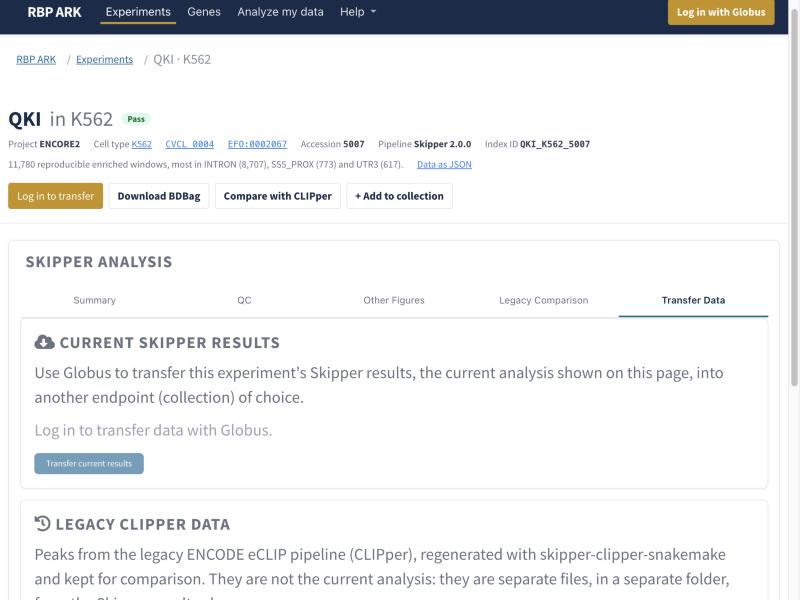

In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
import workflow_utils as U

ROOT, DATA = U.folders()
RESULTS = ROOT / "results" / "workflow"
API_CACHE = DATA / "downloads" / "rbpark_api"
print("case study folder:", ROOT)
print("data folder:", DATA)
import subprocess
import tarfile

## A BDBag

A BDBag is a few kB. Its `fetch.txt` lists each file's address, size and path.

In [ ]:
bag = U.fetch(f"{U.RBPARK}/search/detail/QKI_K562_5007/bdbag/", API_CACHE / "QKI_K562_5007.bdbag.tar.gz")
with tarfile.open(bag) as tar:
    fetch_txt = tar.extractfile(next(m for m in tar.getmembers() if m.name.endswith("fetch.txt"))).read().decode()
listed = pd.DataFrame([line.split("\t") for line in fetch_txt.splitlines()], columns=["url", "size", "path"])
listed["size"] = listed["size"].astype("int64")
print(len(listed), "files, {:.1f} GB in all".format(listed["size"].sum() / 1e9))
listed[listed["path"].str.contains("/bams/dedup/")]

To download a whole bag from a terminal (about 6 GB for this experiment):

```bash
pip install bdbag
tar xzf QKI_K562_5007.bdbag.tar.gz
bdbag --resolve-fetch all QKI_K562_5007
```

## Globus, for many files

Sign in at [app.globus.org](https://app.globus.org), open the RBP-ARK collection (`9cd9be17-cbed-4b34-ab76-704b2fd6ac7b`) and transfer folders to your own endpoint, for example your laptop with [Globus Connect Personal](https://www.globus.org/globus-connect-personal). The same from a terminal:

```bash
pip install globus-cli
globus login
RBPARK=9cd9be17-cbed-4b34-ab76-704b2fd6ac7b
OUT=/encore2/eclip/Skipper/2.0.0/v2/output
globus ls "$RBPARK:$OUT/secondary_results/bams/dedup/genome/" | grep QKI
globus transfer "$RBPARK:$OUT/secondary_results/bams/dedup/genome/QKI_K562_5007_IP_1.genome.Aligned.sort.dedup.bam" \
    "$(globus endpoint local-id):$HOME/rbpark/QKI_K562_5007_IP_1.genome.Aligned.sort.dedup.bam"
```

## The BAMs for the splice maps

Each splice map compares an IP sample with its size-matched input. `eclip_bams()` finds the deduplicated BAMs of both replicates in each experiment's file list. `download_large()` resumes a partial download and checks the SHA-256 checksum, so a file already on disk is not downloaded again.

In lite mode (free Colab) nothing is downloaded here. The lite BAMs in `lite_data/eclip/` hold only the reads the splice maps use: read 2 within 400 nt of every splice site of the exons in the maps, a small part of each file. Next to them, `library_sizes.tsv` keeps each full BAM's read count, so notebook 07 scales the signal as if it came from the full BAM.

In [ ]:
bams = U.eclip_bams(API_CACHE)
print("{} files, {:.1f} GB".format(len(bams), bams["size"].sum() / 1e9))
bams[["subject", "sample", "size", "collection_path"]]

In [ ]:
if U.LITE:
    lite = U.lite_eclip_bams()
    bams = bams.merge(lite[["subject", "sample", "bam", "mapped_F260", "mapped_records", "kept_reads"]], on=["subject", "sample"])
    print("lite mode: using", len(bams), "BAMs from", U.LITE_DIR / "eclip")
else:
    ECLIP_DIR = DATA / "rbp_ark_eclip_skipper2" / "full"
    local = []
    for _, row in bams.iterrows():
        out = ECLIP_DIR / Path(row["collection_path"]).name
        print("checking" if out.exists() else "downloading", out.name, flush=True)
        U.download_large(row["url"], out, row["size"], row["sha256"])
        if not Path(str(out) + ".bai").exists():
            subprocess.check_call(["samtools", "index", str(out)])
        local.append(str(out))
    bams["bam"] = local
bams.to_csv(RESULTS / "03_eclip_bams.tsv", sep="\t", index=False)
bams.drop(columns=["url", "collection_path", "sha256"])